# Identifying Musical Style from Audio Features: A Case Study of Angine de Poitrine

**Course:** DT2470 Music Informatics  
**Group Members:** Johanna Genander, Fanny Nyberg, Filip Svebeck  
**Examiner:** Bobby Lee Townsend Sturm Jr.

## Research Question

Can the unusual musical style of Angine de Poitrine (AdP) be identified from audio features alone, and which measurable characteristics, particularly rhythmic irregularity and microtonality, separate it from conventional rock?

In this project, microtonality is operationalized as pitch deviation from the nearest 12-tone equal temperament semitone (12-TET).

## Hypotheses

- **H1 (rhythm):** AdP exhibits greater rhythmic irregularity than GTZAN rock.
- **H2 (pitch):** AdP deviates more from 12-TET.
- **H3 (classification):** Rhythm and pitch features separate AdP from GTZAN rock clearly above a majority-class baseline, a classifier that always predicts the most frequent class.

## Dataset

The dataset contains two classes: AdP and GTZAN rock, with GTZAN rock serving as the conventional-rock comparison set.

The AdP material consists of 12 tracks from Angine de Poitrine's two albums, *Vol. 1* and *Vol. 2*. The original recordings were converted to mono WAV at 22,050 Hz and divided into 30-second excerpts. A maximum of eight excerpts was retained from each track, resulting in 96 AdP clips.

The comparison class consists of 100 30-second excerpts from the rock category of the GTZAN Genre Collection [3]. This results in a nearly balanced dataset of 196 audio clips in total. The GTZAN files used in this project were obtained from the dataset's Kaggle distribution.

Because several AdP excerpts originate from the same song, the original source track is retained throughout the analysis. During classification, excerpts from the same track are kept within the same cross-validation fold to prevent information from the same recording appearing in both training and test data.

## Notebook Overview

The notebook is organized as follows:

1. **Data Preparation:** Converts and segments the audio and constructs the dataset manifest.
2. **Feature Extraction:** Extracts rhythm, pitch/tonal, and timbral audio features.
3. **Hypothesis Analysis:** Directly evaluates H1 and H2 using the main rhythm and pitch measures.
4. **Classification:** Evaluates H3 using logistic regression and support vector machine (SVM) under grouped cross-validation and compares different feature families.
5. **Recording-Bandwidth Confound Check:** Examines whether differences in recording bandwidth may explain the strong timbre classification results.
6. **Conclusion:** Summarizes the evidence for H1–H3, the main findings, and the limitations of the study.

## 0. Setup

Import the libraries for audio processing, statistical analysis, visualization, and classification. Define shared analysis parameters, set the random seed for reproducibility, and create folders for processed audio, cached results, and figures. Warnings are supressed for a clean output.


In [1]:
from pathlib import Path
import subprocess

import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import matplotlib.pyplot as plt

from scipy import stats
from scipy.signal import butter, sosfiltfilt

from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    confusion_matrix,
    f1_score,
    make_scorer,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    StratifiedGroupKFold,
    cross_val_predict,
    cross_validate,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

SEED = 42
SR = 22050
SEG_SEC = 30
TARGET_DBFS = -20.0
MAX_SEG_PER_TRACK = 8

WIN = int(0.025 * SR)
HOP = int(0.010 * SR)
N_FFT = 2048
N_MFCC = 13

PITCH_WIN = int(0.100 * SR)
PITCH_HOP = PITCH_WIN // 10

RAW_ADP = Path("raw-data/adp")
RAW_ROCK = Path("raw-data/rock")
WAV_ADP = Path("data/interim/adp_wav")
SEG_ADP = Path("data/processed/adp")
CACHE = Path("cache")
FIGS = Path("figures")

for folder in [WAV_ADP, SEG_ADP, CACHE, FIGS]:
    folder.mkdir(parents=True, exist_ok=True)


In [2]:
import warnings
from tqdm import TqdmWarning

warnings.filterwarnings(
    "ignore",
    message="invalid value encountered in cast",
    category=RuntimeWarning
)

warnings.filterwarnings(
    "ignore",
    category=TqdmWarning
)


## 1. Data Preparation

The two classes are converted to a common analysis format: mono audio at 22,050 Hz and 30-second duration. Each AdP track contributes at most eight evenly spaced excerpts, preventing longer songs from dominating the dataset.

Because several AdP excerpts originate from the same song, the original `source_track` is retained. This is later used to keep all excerpts from one song in the same cross-validation fold and avoid train-test leakage.


### 1.1 Prepare the AdP Audio

The purchased `.m4a` files are converted to WAV and divided into 30-second excerpts. Eight segments are sampled across each track rather than taking only the beginning of each song.


In [3]:
adp_files = sorted(RAW_ADP.rglob("*.m4a"))
assert adp_files, f"No .m4a files found in {RAW_ADP}"

for src in adp_files:
    dst = WAV_ADP / f"{src.stem}.wav"
    if not dst.exists():
        subprocess.run(
            [
                "ffmpeg", "-y", "-i", str(src), "-vn",
                "-ac", "1", "-ar", str(SR), str(dst)
            ],
            check=True,
            stdout=subprocess.DEVNULL,
            stderr=subprocess.DEVNULL,
        )

segment_records = []

for wav_path in sorted(WAV_ADP.glob("*.wav")):
    y, _ = librosa.load(wav_path, sr=SR, mono=True)
    segment_len = SEG_SEC * SR
    n_segments = len(y) // segment_len
    n_keep = min(n_segments, MAX_SEG_PER_TRACK)

    if n_keep == 0:
        continue

    selected = np.linspace(0, n_segments - 1, n_keep, dtype=int)

    for seg_idx in selected:
        start = seg_idx * segment_len
        clip = y[start:start + segment_len]
        out_path = SEG_ADP / f"{wav_path.stem}_seg{seg_idx:02d}.wav"
        sf.write(out_path, clip, SR)

        segment_records.append({
            "path": str(out_path),
            "label": 1,
            "label_name": "adp",
            "source_track": wav_path.stem,
            "segment_idx": seg_idx,
        })


### 1.2 Build the Dataset Manifest

Each excerpt is stored with its path, class label, and source-track identity. GTZAN already consists of 30-second excerpts [3], so its 100 rock files can be added directly.


In [4]:
rock_files = sorted(RAW_ROCK.rglob("*.wav"))
assert len(rock_files) >= 100, f"Expected 100 rock clips, found {len(rock_files)}"

rock_records = [{
    "path": str(path),
    "label": 0,
    "label_name": "rock",
    "source_track": path.stem,
    "segment_idx": 0,
} for path in rock_files[:100]]

manifest = pd.DataFrame(segment_records + rock_records)
manifest.insert(0, "clip_id", [f"clip_{i:03d}" for i in range(len(manifest))])

assert manifest["path"].map(lambda p: Path(p).exists()).all(),     "At least one audio path in the manifest does not exist."

manifest.groupby("label_name").agg(
    n_clips=("clip_id", "count"),
    n_tracks=("source_track", "nunique"),
)


,n_clips,n_tracks
label_name,,
adp,96,12
rock,100,100


### Dataset Result

The final dataset contains 196 excerpts: 96 AdP clips from 12 source tracks and 100 GTZAN rock excerpts, each treated as a separate source group. The class sizes are therefore nearly balanced.

The unequal number of independent source tracks is important: AdP has eight excerpts per song, whereas each GTZAN excerpt is treated as a separate source. Statistical tests therefore aggregate AdP excerpts to the track level, and classification uses grouped cross-validation.


## 2. Feature Extraction

This follows a standard music information retrieval (MIR) workflow in which the audio signal is converted into musically meaningful features before analysis or classification [1, Sec. 3.1]. More generally, feature extraction is a preprocessing step that maps raw inputs into variables intended to preserve discriminative information [2, Ch. 1].

Three complementary feature families are used:
- Rhythm (`rhy_`): tempo, onset timing, pulse clarity, and rhythmic variability.
- Pitch (`pit_`): chroma, tuning, spectral pitch-grid alignment, and estimated fundamental frequency.
- Timbre (`tim_`): Mel-frequency cepstral coefficients (MFCCs) and spectral descriptors of the overall sound.

The two hypothesis-driven features are `rhy_ioi_cv` for rhythmic irregularity and `pit_yin_dev_mean` for deviation from 12-TET. Timbre is included as a comparison feature family to determine whether AdP is easier to identify from its overall sound than from the two proposed stylistic mechanisms.

### Parameter choices

All recordings are analyzed at 22,050 Hz and in 30-second excerpts to ensure a common input format. MFCCs and the custom short-time descriptors use a 25 ms analysis window and 10 ms hop, while additional spectral descriptors are computed using standard `librosa` settings with the same 10 ms hop. Pitch-oriented analysis uses approximately 100 ms frames to provide greater frequency resolution. Thirteen MFCCs are retained as a compact timbral representation. The same parameter settings are applied to both classes throughout the analysis.


### 2.1 Shared Helpers

All clips are loaded at the same sampling rate, fixed to 30 seconds, and root-mean-square (RMS) normalized before feature extraction so that overall loudness cannot act as a simple class cue.


In [5]:
def zero_crossings_per_frame(x, frame_size, hop_size):
    # Number of sign changes in each complete frame.
    x = np.asarray(x)
    crossings = []

    for start in range(0, len(x) - frame_size + 1, hop_size):
        frame = x[start:start + frame_size]
        signs = np.where(frame >= 0, 1, -1)
        crossings.append(np.count_nonzero(signs[:-1] != signs[1:]))

    return np.asarray(crossings, dtype=int)


def spectral_centroid_per_frame(x, frame_size, hop_size, sample_rate):
    # Spectral centroid in Hz for each complete frame.
    x = np.asarray(x, dtype=np.float64)
    frequencies = np.fft.rfftfreq(frame_size, d=1 / sample_rate)
    centroids = []

    for start in range(0, len(x) - frame_size + 1, hop_size):
        magnitude = np.abs(np.fft.rfft(x[start:start + frame_size]))
        denominator = magnitude.sum()
        value = (
            np.dot(frequencies, magnitude) / denominator
            if denominator > 0
            else 0.0
        )
        centroids.append(value)

    return np.asarray(centroids, dtype=np.float64)


def load_clip(path):
    # Load one clip and remove global loudness as a class cue.
    y, _ = librosa.load(path, sr=SR, mono=True)
    y = librosa.util.fix_length(y, size=SEG_SEC * SR)

    rms = np.sqrt(np.mean(y ** 2)) + 1e-12
    y = y * (10 ** (TARGET_DBFS / 20) / rms)

    peak = np.max(np.abs(y))
    return y / peak if peak > 1 else y


def entropy(values):
    # Shannon entropy [2, Sec. 1.6].
    p = np.clip(np.asarray(values, dtype=float), 0, None)
    if p.sum() <= 0:
        return np.nan

    p = p[p > 0] / p.sum()
    return float(-(p * np.log2(p)).sum())


def dynamic_tempo(onset_env):
    # librosa moved this function between versions.
    try:
        return librosa.feature.rhythm.tempo(
            onset_envelope=onset_env,
            sr=SR,
            hop_length=HOP,
            aggregate=None,
        )
    except AttributeError:
        return librosa.beat.tempo(
            onset_envelope=onset_env,
            sr=SR,
            hop_length=HOP,
            aggregate=None,
        )


### 2.2 Rhythm Features

Onset, i.e. detected beginnings of musical events, tempo analysis, tempograms, and beat tracking are standard tools for describing rhythmic structure in audio [1, Ch. 6]. A tempogram is a time-varying representation of rhythmic periodicity/tempo. Here, rhythmic irregularity is represented primarily by the coefficient of variation (CV) of inter-onset intervals (IOIs):

$$
CV_{\mathrm{IOI}} = \frac{\sigma_{\mathrm{IOI}}}{\mu_{\mathrm{IOI}}}
$$

A higher `rhy_ioi_cv` means that detected onsets are spaced less regularly relative to their average spacing. Under H1, AdP is therefore expected to have a higher value than GTZAN rock. Tempo variation, onset rate, pulse clarity, tempogram entropy, and beat-synchronization deviation provide complementary rhythmic information.


In [6]:
def rhythm_features(y):
    # Onset/tempo descriptors follow the rhythm-analysis concepts in [1, Ch. 6].
    onset_env = librosa.onset.onset_strength(y=y, sr=SR, hop_length=HOP)

    tempo, beats = librosa.beat.beat_track(
        onset_envelope=onset_env,
        sr=SR,
        hop_length=HOP,
        units="time",
    )
    onsets = librosa.onset.onset_detect(
        onset_envelope=onset_env,
        sr=SR,
        hop_length=HOP,
        units="time",
    )

    f = {
        "rhy_tempo": float(np.atleast_1d(tempo)[0]),
        "rhy_beat_count": float(len(beats)),
        "rhy_tempo_std": float(np.std(dynamic_tempo(onset_env))),
        "rhy_onset_rate": len(onsets) / SEG_SEC,
    }

    ioi = np.diff(onsets)
    if len(ioi) >= 3:
        f["rhy_ioi_mean"] = float(np.mean(ioi))
        f["rhy_ioi_std"] = float(np.std(ioi))
        f["rhy_ioi_cv"] = float(np.std(ioi) / (np.mean(ioi) + 1e-9))
        f["rhy_ioi_entropy"] = entropy(
            np.histogram(ioi, bins=20, range=(0, 2))[0]
        )
    else:
        f.update(
            rhy_ioi_mean=np.nan,
            rhy_ioi_std=np.nan,
            rhy_ioi_cv=np.nan,
            rhy_ioi_entropy=np.nan,
        )

    ac = librosa.autocorrelate(onset_env, max_size=len(onset_env) // 2)
    ac = ac / (ac[0] + 1e-9)
    lag_min = int(round(0.25 * SR / HOP))
    f["rhy_pulse_clarity"] = (
        float(ac[lag_min:].max()) if len(ac) > lag_min else np.nan
    )

    tempogram = librosa.feature.tempogram(
        onset_envelope=onset_env,
        sr=SR,
        hop_length=HOP,
    )
    f["rhy_tempogram_entropy"] = entropy(np.abs(tempogram).mean(axis=1))

    if len(beats) > 2 and len(onsets) > 0:
        deviation = np.abs(onsets[:, None] - beats[None, :]).min(axis=1)
        beat_period = np.median(np.diff(beats))
        f["rhy_beat_sync_dev"] = float(
            np.mean(deviation) / (beat_period + 1e-9)
        )
    else:
        f["rhy_beat_sync_dev"] = np.nan

    f["rhy_onset_env_mean"] = float(np.mean(onset_env))
    f["rhy_onset_env_std"] = float(np.std(onset_env))
    return f


### 2.3 Pitch and Tonal Features

The pitch representation is based on the 12-tone equal-tempered scale, where one octave is divided into 12 logarithmically spaced semitones and one semitone corresponds to 100 cents [1, Sec. 1.3.2]. A log-frequency representation is first constructed and then folded into 12 pitch classes to obtain a chromagram, following the standard chroma construction described in [1, Sec. 3.1.2].

Microtonality is measured more directly from estimated fundamental frequencies (F0). Probabilistic YIN (pYIN) identifies reliably pitched frames [4], YIN supplies a continuous-frequency estimate [5], and accepted pitches are measured in cents from the nearest 12-TET semitone after correcting for the clip's global tuning offset. Estimating $F0$ in polyphonic mixtures is inherently difficult because several sound sources and harmonics overlap in the same recording [1, Sec. 8.2].

The main H2 variable is `pit_yin_dev_mean`. A larger value means that the accepted pitch estimates lie, on average, further from the nearest equal-tempered semitone. Spectral-peak grid features are retained as complementary pitch descriptors.

In addition to chroma and F0-based measures, a custom spectral-peak heuristic is used to measure how strongly prominent spectral peaks align with a common 100-cent semitone grid.


In [7]:
def f_pitch(p):
    # 12-TET pitch-to-frequency mapping: [1, Eq. (1.1)].
    return 440 * 2 ** ((p - 69) / 12)


def find_anchors(Sdb, sr, hop_length, dT=0.100, n_bands=25):
    # Loudest point in each time-frequency box.
    n_bins, n_frames = Sdb.shape
    dt_frames = int(round(dT * sr / hop_length))
    band_edges = np.linspace(0, n_bins, n_bands + 1).astype(int)

    t_idx, f_idx, db = [], [], []

    for t0 in range(0, n_frames, dt_frames):
        t1 = min(t0 + dt_frames, n_frames)

        for band in range(n_bands):
            f0, f1 = band_edges[band], band_edges[band + 1]
            box = Sdb[f0:f1, t0:t1]

            if box.size == 0:
                continue

            k, n = np.unravel_index(np.argmax(box), box.shape)
            t_idx.append(t0 + n)
            f_idx.append(f0 + k)
            db.append(box[k, n])

    return np.array(t_idx), np.array(f_idx), np.array(db)


F_COEF = np.arange(PITCH_WIN // 2 + 1) * SR / PITCH_WIN
PITCH_MASKS = [
    (F_COEF >= f_pitch(p - 0.5)) & (F_COEF < f_pitch(p + 0.5))
    for p in range(128)
]


def log_frequency_spectrum(X):
    # Pool short-time Fourier transform (STFT) power into Musical Instrument Digital Interface (MIDI) pitch bands as in [1, Sec. 3.1.1].
    power = np.abs(X) ** 2
    return np.array([
        power[mask].sum(axis=0) if mask.any() else np.zeros(X.shape[1])
        for mask in PITCH_MASKS
    ])


def chromagram(Y):
    # Fold octave-equivalent pitch bands into 12 chroma classes [1, Sec. 3.1.2].
    chroma = np.zeros((12, Y.shape[1]))

    for pitch in range(128):
        chroma[pitch % 12] += Y[pitch]

    return np.log1p(100 * chroma)


def parabolic_refine(column_db, k):
    # Refine a spectral peak to a sub-bin position.
    if k <= 0 or k >= len(column_db) - 1:
        return 0.0

    a, b, c = column_db[k - 1], column_db[k], column_db[k + 1]
    denominator = a - 2 * b + c

    if denominator == 0:
        return 0.0

    return float(
        np.clip(0.5 * (a - c) / denominator, -0.5, 0.5)
    )


def cents_from_semitone_grid(freqs_hz, tuning_semitones):
    # Cent conversion follows the logarithmic interval definition in [1, Eq. (1.4)].
    cents = 1200 * np.log2(np.asarray(freqs_hz) / 440.0)
    cents -= 100 * tuning_semitones
    return np.abs(((cents + 50) % 100) - 50)


def grid_concentration(freqs_hz):
    # Concentration of spectral peaks around one common 100-cent grid.
    cents = 1200 * np.log2(np.asarray(freqs_hz) / 440.0)
    angles = 2 * np.pi * ((cents % 100) / 100.0)

    C = np.cos(angles).mean()
    S = np.sin(angles).mean()

    concentration = float(np.hypot(C, S))
    offset = float(np.arctan2(S, C) / (2 * np.pi) * 100)
    deviation = float(
        np.abs(((cents - offset + 50) % 100) - 50).mean()
    )

    return concentration, offset, deviation


F0_MIN = librosa.note_to_hz("C2")
F0_MAX = librosa.note_to_hz("C6")
F0_HOP = 1024


def f0_features(y):
    # pYIN [4] selects reliable pitched frames; YIN [5] supplies continuous F0 estimates.
    harmonic = librosa.effects.harmonic(y, margin=3.0)

    f0_pyin, voiced_flag, voiced_prob = librosa.pyin(
        harmonic,
        fmin=F0_MIN,
        fmax=F0_MAX,
        sr=SR,
        frame_length=N_FFT,
        hop_length=F0_HOP,
    )
    f0_yin = librosa.yin(
        harmonic,
        fmin=F0_MIN,
        fmax=F0_MAX,
        sr=SR,
        frame_length=N_FFT,
        hop_length=F0_HOP,
    )

    n = min(len(f0_yin), len(f0_pyin))
    f0_yin = f0_yin[:n]
    f0_pyin = f0_pyin[:n]
    voiced_flag = voiced_flag[:n]
    voiced_prob = voiced_prob[:n]

    with np.errstate(invalid="ignore", divide="ignore"):
        agreement = np.abs(1200 * np.log2(f0_yin / f0_pyin)) < 50

    voiced = (
        voiced_flag
        & (voiced_prob > 0.5)
        & np.isfinite(f0_pyin)
        & agreement
    )

    f = {"pit_voiced_fraction": float(voiced.mean())}

    if voiced.sum() < 20:
        f.update(
            pit_f0_tuning=np.nan,
            pit_yin_dev_mean=np.nan,
            pit_yin_dev_std=np.nan,
            pit_f0_offgrid_frac=np.nan,
            pit_f0_median=np.nan,
            pit_f0_iqr=np.nan,
        )
        return f

    f0 = f0_yin[voiced]
    tuning = float(librosa.pitch_tuning(f0))
    deviation = cents_from_semitone_grid(f0, tuning)

    f["pit_f0_tuning"] = tuning
    f["pit_yin_dev_mean"] = float(np.mean(deviation))
    f["pit_yin_dev_std"] = float(np.std(deviation))
    f["pit_f0_offgrid_frac"] = float(np.mean(deviation > 25))
    f["pit_f0_median"] = float(np.median(f0))
    f["pit_f0_iqr"] = float(np.subtract(*np.percentile(f0, [75, 25])))

    return f


def tonal_features(y):
    tuning = float(librosa.estimate_tuning(y=y, sr=SR))

    X = librosa.stft(
        y,
        n_fft=PITCH_WIN,
        win_length=PITCH_WIN,
        hop_length=PITCH_HOP,
        window="hann",
    )

    chroma = chromagram(log_frequency_spectrum(X))
    chroma_mean = chroma.mean(axis=1)

    f = {"pit_tuning_offset": tuning}

    for i, value in enumerate(chroma_mean):
        f[f"pit_chroma_{i:02d}"] = float(value)

    f["pit_chroma_entropy"] = entropy(chroma_mean)
    f["pit_chroma_std"] = float(chroma.std(axis=1).mean())

    # Spectral-peak alignment to a common semitone grid.
    Sdb = librosa.amplitude_to_db(np.abs(X), ref=np.max)
    t_idx, f_idx, db = find_anchors(Sdb, SR, PITCH_HOP)
    bin_hz = SR / PITCH_WIN

    keep = np.flatnonzero(
        (db > -40)
        & (f_idx > 2)
        & (f_idx < Sdb.shape[0] - 3)
    )

    if len(keep) > 20:
        peaks = np.array([
            (
                f_idx[i]
                + parabolic_refine(Sdb[:, t_idx[i]], f_idx[i])
            ) * bin_hz
            for i in keep
        ])
        peaks = peaks[(peaks > 80) & (peaks < 1500)]
    else:
        peaks = np.array([])

    if len(peaks) > 20:
        concentration, offset, deviation = grid_concentration(peaks)
        f["pit_grid_concentration"] = concentration
        f["pit_peak_tuning_cents"] = offset
        f["pit_peak_dev_mean"] = deviation
    else:
        f.update(
            pit_grid_concentration=np.nan,
            pit_peak_tuning_cents=np.nan,
            pit_peak_dev_mean=np.nan,
        )

    f.update(f0_features(y))
    return f


### 2.4 Timbre Features

Timbre describes perceptual differences in sound quality that are strongly related to spectral energy distribution and harmonic structure [1, Sec. 1.3.4], [3]. In this project, timbre is represented using standard music information retrieval (MIR) descriptors: zero-crossing statistics, spectral centroid, 13 MFCCs, spectral bandwidth, rolloff, flatness, and frame-level RMS statistics. Because recordings are globally RMS-normalized beforehand, the latter primarily reflect within-clip energy variation rather than overall recording level.

These features are not part of H1 or H2. They are included to test whether the classes differ more strongly in their overall spectral and production characteristics than in rhythm or tuning.


In [8]:
def timbre_features(y):
    f = {}

    zc = zero_crossings_per_frame(y, WIN, HOP)
    sc = spectral_centroid_per_frame(
        y,
        WIN + WIN % 2,
        HOP,
        SR,
    )

    f["tim_zc_mean"] = float(zc.mean())
    f["tim_zc_std"] = float(zc.std())
    f["tim_sc_mean"] = float(sc.mean())
    f["tim_sc_std"] = float(sc.std())

    mfcc = librosa.feature.mfcc(
        y=y,
        sr=SR,
        n_mfcc=N_MFCC,
        n_fft=N_FFT,
        win_length=WIN,
        hop_length=HOP,
        window="hann",
    )

    for i in range(N_MFCC):
        f[f"tim_mfcc{i:02d}_mean"] = float(mfcc[i].mean())
        f[f"tim_mfcc{i:02d}_std"] = float(mfcc[i].std())

    descriptors = {
        "bandwidth": librosa.feature.spectral_bandwidth(
            y=y,
            sr=SR,
            hop_length=HOP,
        )[0],
        "rolloff": librosa.feature.spectral_rolloff(
            y=y,
            sr=SR,
            hop_length=HOP,
        )[0],
        "flatness": librosa.feature.spectral_flatness(
            y=y,
            hop_length=HOP,
        )[0],
        "rms": librosa.feature.rms(
            y=y,
            hop_length=HOP,
        )[0],
    }

    for name, values in descriptors.items():
        f[f"tim_{name}_mean"] = float(values.mean())
        f[f"tim_{name}_std"] = float(values.std())

    return f


### 2.5 Extract Features for All Clips

The three feature families are concatenated into one fixed-length feature vector for each excerpt. Features are cached after extraction because pitch estimation is computationally expensive.


In [9]:
def extract_all(path):
    y = load_clip(path)
    f = {}
    f.update(rhythm_features(y))
    f.update(tonal_features(y))
    f.update(timbre_features(y))
    return f


FEATURE_CACHE = CACHE / "features_submission.csv"

if FEATURE_CACHE.exists():
    features = pd.read_csv(FEATURE_CACHE)
    same_manifest = (
        len(features) == len(manifest)
        and features["clip_id"].tolist() == manifest["clip_id"].tolist()
        and features["path"].tolist() == manifest["path"].tolist()
    )
else:
    same_manifest = False

if not same_manifest:
    rows = []
    for i, row in enumerate(manifest.itertuples(), 1):
        rows.append({"clip_id": row.clip_id, **extract_all(row.path)})

    features = manifest.merge(pd.DataFrame(rows), on="clip_id")
    features.to_csv(FEATURE_CACHE, index=False)

FEATURE_COLS = [
    c for c in features.columns
    if c.startswith(("rhy_", "pit_", "tim_"))
]

print(
    f"{len(features)} clips, {len(FEATURE_COLS)} features "
    f"({sum(c.startswith('rhy_') for c in FEATURE_COLS)} rhythm, "
    f"{sum(c.startswith('pit_') for c in FEATURE_COLS)} pitch, "
    f"{sum(c.startswith('tim_') for c in FEATURE_COLS)} timbre)"
)


196 clips, 76 features (13 rhythm, 25 pitch, 38 timbre)


### Extracted Feature Set

Feature extraction produced 76 features for each of the 196 clips: 13 rhythm features, 25 pitch features, and 38 timbre features. This feature table is used for the hypothesis tests and classification experiments below.


## 3. Hypothesis Analysis

H1 and H2 are evaluated directly before classification. The histograms show the distribution of the two main features at the clip level, while statistical inference is performed at the source-track level by taking the median value per track.

This prevents the eight AdP excerpts from each song from being treated as eight independent observations. Group differences are tested with a two-sided Mann–Whitney U test using a significance level of $\alpha = 0.05$ and summarized with Cliff's delta, a non-parametric effect-size measure ranging from −1 to 1. Positive values indicate higher values for AdP and negative values indicate higher values for GTZAN rock [6], [7].


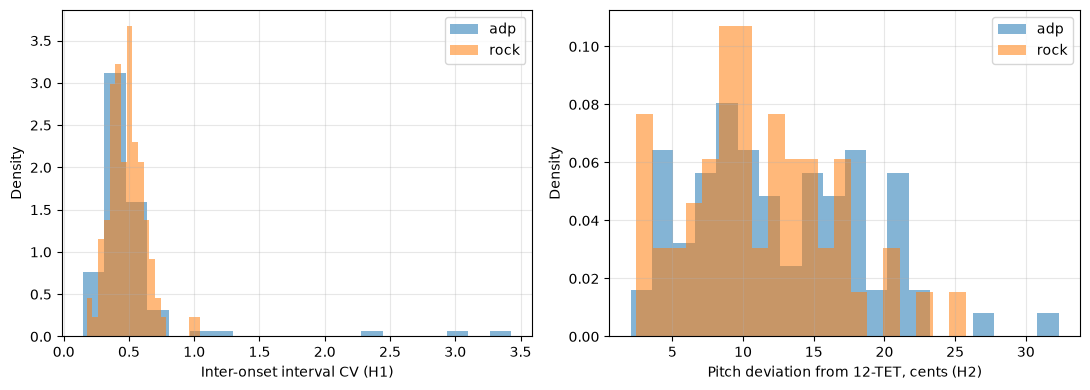

In [10]:
KEY_FEATURES = {
    "rhy_ioi_cv": "Inter-onset interval CV (H1)",
    "pit_yin_dev_mean": "Pitch deviation from 12-TET, cents (H2)",
}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, (feature, label) in zip(axes, KEY_FEATURES.items()):
    for class_name in ["adp", "rock"]:
        values = features.loc[
            features["label_name"] == class_name, feature
        ].dropna()

        ax.hist(
            values,
            bins=20,
            alpha=0.55,
            density=True,
            label=class_name,
        )

    ax.set_xlabel(label)
    ax.set_ylabel("Density")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(FIGS / "hypothesis_features.pdf", bbox_inches="tight")
plt.show()


In [11]:
def cliffs_delta(a, b):
    # Cliff's delta [7].
    a = np.asarray(a)
    b = np.asarray(b)
    greater = (a[:, None] > b[None, :]).sum()
    less = (a[:, None] < b[None, :]).sum()
    return float(greater - less) / (len(a) * len(b))


def track_level_test(feature):
    track_values = (
        features.groupby(
            ["label", "label_name", "source_track"],
            as_index=False,
        )[feature]
        .median()
        .dropna(subset=[feature])
    )

    adp = track_values.loc[track_values["label"] == 1, feature].values
    rock = track_values.loc[track_values["label"] == 0, feature].values

    _, p_value = stats.mannwhitneyu(
        # Mann–Whitney U test [6].
        adp,
        rock,
        alternative="two-sided",
    )

    return {
        "feature": feature,
        "n_adp": len(adp),
        "n_rock": len(rock),
        "median_adp": np.median(adp),
        "median_rock": np.median(rock),
        "cliffs_delta": cliffs_delta(adp, rock),
        "p_value": p_value,
    }


hypothesis_tests = pd.DataFrame([
    track_level_test(feature)
    for feature in KEY_FEATURES
])

hypothesis_tests.round(3)


,feature,n_adp,n_rock,median_adp,median_rock,cliffs_delta,p_value
0,rhy_ioi_cv,12,100,0.418,0.481,-0.25,0.160
1,pit_yin_dev_mean,11,56,11.750,10.359,0.13,0.504


### H1 and H2 Results

H1 is not supported by `rhy_ioi_cv`. The track-level median is 0.418 for AdP and 0.481 for GTZAN rock. The observed direction is therefore opposite to H1: AdP is slightly less irregular on this onset-spacing measure. The effect size is Cliff's $\delta=-0.25$, with $p=0.160$.

H2 is also not supported statistically. AdP has a somewhat larger median deviation from 12-TET (11.75 cents) than rock (10.36 cents). The effect size is Cliff's $\delta=0.13$, with $p=0.504$. Reliable F0 estimates are available for only 11 AdP tracks and 56 rock tracks, which further limits this comparison.

Taken together, the direct tests do not show that greater onset irregularity or greater pitch deviation alone explains what makes AdP different from the GTZAN rock comparison set.


## 4. Classification

H3 tests whether the extracted features can identify AdP even though H1 and H2 are weak individually. This is a supervised classification problem: labeled feature vectors are used to learn a decision rule that should generalize to unseen examples [2, Ch. 1].

Models are evaluated with five-fold stratified grouped cross-validation, implemented with `StratifiedGroupKFold`, keeping every excerpt from the same source track in one fold. Imputation and standardization are fitted inside each training fold so that preprocessing is learned only from the training data.

F0-based features used in the direct H2 analysis are excluded from classification because reliable F0 estimates are unavailable for many clips. Including heavily missing features could allow missingness itself to influence classification. The pitch feature family used for H3 therefore consists primarily of chroma, tuning, spectral pitch-grid, and related tonal descriptors.

The majority-class model provides a simple baseline. Logistic regression is used as a linear probabilistic classifier [2, Sec. 4.3.2], while a radial basis function (RBF) support vector machine (SVM) provides a nonlinear kernel-based classifier [2, Ch. 7]. Performance is summarized with accuracy, precision, recall, and F1-score, the harmonic mean of precision and recall. Precision, recall, and F-measure are standard evaluation measures in MIR [1, Sec. 4.5.1].


In [12]:
F0_COLS = [
    "pit_yin_dev_mean",
    "pit_yin_dev_std",
    "pit_f0_offgrid_frac",
    "pit_f0_tuning",
    "pit_f0_median",
    "pit_f0_iqr",
]

MODEL_COLS = [c for c in FEATURE_COLS if c not in F0_COLS]

FEATURE_SETS = {
    "rhythm": [c for c in MODEL_COLS if c.startswith("rhy_")],
    "pitch": [c for c in MODEL_COLS if c.startswith("pit_")],
    "timbre": [c for c in MODEL_COLS if c.startswith("tim_")],
}
FEATURE_SETS["rhythm + pitch"] = (
    FEATURE_SETS["rhythm"] + FEATURE_SETS["pitch"]
)
FEATURE_SETS["all"] = MODEL_COLS

y = features["label"].to_numpy()
groups = features["source_track"].to_numpy()

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED,
)

SCORING = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
}


def make_models():
    # Logistic regression: [2, Sec. 4.3.2]; support vector machines: [2, Ch. 7].
    return {
        "Majority baseline": DummyClassifier(strategy="most_frequent"),
        "Logistic regression": make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            LogisticRegression(max_iter=5000),
        ),
        "SVM (RBF)": make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            SVC(kernel="rbf", C=1.0, gamma="scale"),
        ),
    }


def evaluate(model, columns):
    result = cross_validate(
        model,
        features[columns],
        y,
        groups=groups,
        cv=cv,
        scoring=SCORING,
    )

    metrics = {}
    for metric in SCORING:
        values = result[f"test_{metric}"]
        metrics[metric] = values.mean()
        metrics[f"{metric}_std"] = values.std()
    return metrics


### 4.1 H3: Rhythm and Pitch

H3 is tested first using only the rhythm and pitch feature families. This directly asks whether the musical dimensions motivated by the research question contain enough information to identify AdP.


In [13]:
h3_cols = FEATURE_SETS["rhythm + pitch"]

rows = []
for model_name, model in make_models().items():
    result = evaluate(model, h3_cols)
    rows.append({
        "model": model_name,
        "accuracy": result["accuracy"],
        "precision": result["precision"],
        "recall": result["recall"],
        "f1": result["f1"],
        "f1_std": result["f1_std"],
    })

h3_results = pd.DataFrame(rows).set_index("model")
h3_results.round(3)


,accuracy,precision,recall,f1,f1_std
model,,,,,
Majority baseline,0.515,0.000,0.000,0.000,0.000
Logistic regression,0.873,0.858,0.888,0.870,0.022
SVM (RBF),0.904,0.880,0.929,0.903,0.029


### H3 Result

Both models clearly outperform the majority baseline. The baseline obtains 51.5% accuracy but F1 = 0 because it predicts only the majority rock class.

Using rhythm + pitch, logistic regression reaches 87.3% accuracy and F1 = 0.870, while the RBF SVM reaches 90.4% accuracy and F1 = 0.903. The SVM also has high AdP recall (0.929), meaning that most AdP excerpts are recognized correctly. This supports H3 even though H1 and H2 are not individually significant.


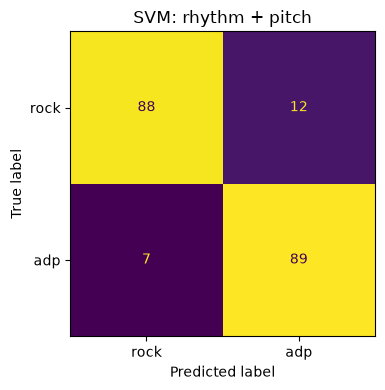

In [14]:
h3_model = make_models()["SVM (RBF)"]
y_pred = cross_val_predict(
    h3_model,
    features[h3_cols],
    y,
    groups=groups,
    cv=cv,
)

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(
    confusion_matrix(y, y_pred),
    display_labels=["rock", "adp"],
).plot(ax=ax, colorbar=False)

ax.set_title("SVM: rhythm + pitch")
plt.tight_layout()
plt.savefig(FIGS / "confusion_h3.pdf", bbox_inches="tight")
plt.show()


### Confusion Matrix

Across the grouped cross-validation predictions, the rhythm + pitch SVM correctly classifies 88 of 100 rock excerpts and 89 of 96 AdP excerpts. It produces 12 rock-to-AdP errors and 7 AdP-to-rock errors.

The relatively balanced error pattern shows that the high F1 score is not produced by favoring only one class.


### 4.2 Feature-Family Ablation

To determine which type of information drives classification, the same models are evaluated using rhythm only, pitch only, timbre only, rhythm + pitch, and all retained features.


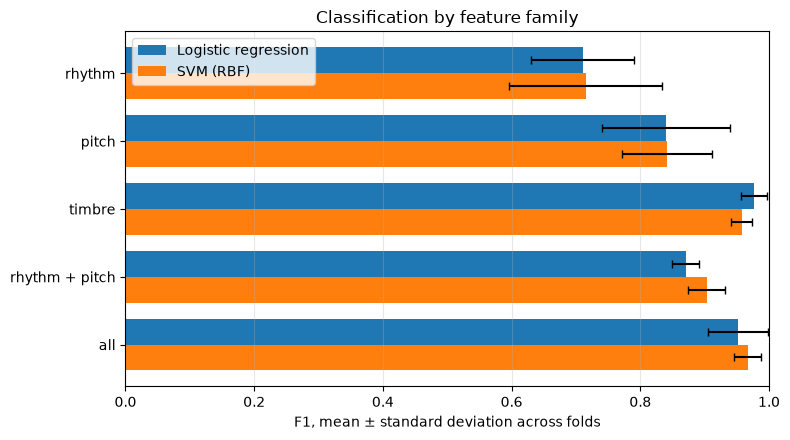

,features,model,f1,f1_std
0,rhythm,Logistic regression,0.711,0.080
1,rhythm,SVM (RBF),0.715,0.119
2,pitch,Logistic regression,0.840,0.099
3,pitch,SVM (RBF),0.841,0.070
4,timbre,Logistic regression,0.977,0.020
5,timbre,SVM (RBF),0.958,0.016
6,rhythm + pitch,Logistic regression,0.870,0.022
7,rhythm + pitch,SVM (RBF),0.903,0.029
8,all,Logistic regression,0.952,0.046
9,all,SVM (RBF),0.967,0.020


In [15]:
rows = []

for set_name, columns in FEATURE_SETS.items():
    for model_name, model in make_models().items():
        if model_name == "Majority baseline":
            continue

        result = evaluate(model, columns)
        rows.append({
            "features": set_name,
            "model": model_name,
            "f1": result["f1"],
            "f1_std": result["f1_std"],
        })

ablation = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8, 4.5))
order = list(FEATURE_SETS)
width = 0.38

for i, (model_name, subset) in enumerate(
    ablation.groupby("model", sort=False)
):
    subset = subset.set_index("features").loc[order]
    positions = np.arange(len(order)) + (i - 0.5) * width

    ax.barh(
        positions,
        subset["f1"],
        xerr=subset["f1_std"],
        height=width,
        label=model_name,
        capsize=3,
    )

ax.set_yticks(np.arange(len(order)), order)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("F1, mean ± standard deviation across folds")
ax.set_title("Classification by feature family")
ax.legend()
ax.grid(True, axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig(FIGS / "ablation.pdf", bbox_inches="tight")
plt.show()

ablation.round(3)


### Feature-Family Results

The ablation, evaluating feature families separately to determine which information drives performance, shows a clear hierarchy. Rhythm alone is weakest (F1 $\approx 0.71$), while pitch alone reaches about 0.84. Combining rhythm and pitch increases performance to 0.870 for logistic regression and 0.903 for the SVM.

The strongest single feature family is timbre: logistic regression reaches F1 = 0.977, and the SVM reaches 0.958. Using all features gives 0.952 and 0.967, respectively, so adding rhythm and pitch does not consistently improve on timbre alone.

This changes the interpretation of H3. AdP is highly identifiable from audio, but the strongest classification performance is obtained from the overall timbral/spectral representation rather than from rhythm or pitch alone.

### Model comparison and improvement

The ablation analysis was also used to improve classification performance. For logistic regression, selecting the timbre representation increased F1 from 0.870 with rhythm + pitch and 0.952 with all retained features to 0.977. For the SVM, including all feature families increased F1 from 0.903 with rhythm + pitch to 0.967. This shows that model performance can be improved through appropriate feature representation rather than simply increasing model complexity.

The RBF SVM performs better than logistic regression for rhythm + pitch (0.903 vs. 0.870), suggesting that some of the separation in these features is nonlinear. In contrast, logistic regression performs best on timbre alone, indicating that the timbral feature space is already highly separable with a linear decision boundary.


## 5. Recording-Bandwidth Confound Check

A confound is a dataset difference unrelated to the intended musical property that may nevertheless drive classification. The timbre result could partly reflect the datasets themselves. The AdP files come from modern digital releases, whereas GTZAN contains older recordings from heterogeneous sources [3], [8]. A classifier might therefore exploit encoding or bandwidth differences instead of musical characteristics.
Two checks are used:

1. Measure the proportion of energy above 9 kHz.
2. Recompute all timbre features after low-pass filtering both classes at 8 kHz, which removes frequency content above a selected cutoff.

The 9 kHz diagnostic threshold and 8 kHz low-pass cutoff are used as simple checks of the upper-frequency region rather than as theoretically fixed boundaries. If timbre classification remains strong after the same low-pass filter is applied to both classes, a simple high-frequency cutoff cannot by itself explain the result.


In [16]:
LOWPASS_HZ = 8000
HF_DIAG_HZ = 9000
SOS = butter(8, LOWPASS_HZ, btype="low", fs=SR, output="sos")


def lowpass(y):
    return sosfiltfilt(SOS, y)


def high_frequency_energy_db(y):
    S = np.abs(librosa.stft(y, n_fft=N_FFT, hop_length=HOP)) ** 2
    freqs = librosa.fft_frequencies(sr=SR, n_fft=N_FFT)
    ratio = S[freqs >= HF_DIAG_HZ].sum() / (S.sum() + 1e-12)
    return float(10 * np.log10(ratio + 1e-12))


LP_CACHE = CACHE / "timbre_lowpass_submission.csv"

if LP_CACHE.exists():
    lowpass_features = pd.read_csv(LP_CACHE)
else:
    rows = []
    for i, row in enumerate(manifest.itertuples(), 1):

        y_clip = load_clip(row.path)
        timbre_lp = timbre_features(lowpass(y_clip))

        rows.append({
            "clip_id": row.clip_id,
            "conf_hf_energy_db": high_frequency_energy_db(y_clip),
            **{f"{key}_lp": value for key, value in timbre_lp.items()},
        })

    lowpass_features = pd.DataFrame(rows)
    lowpass_features.to_csv(LP_CACHE, index=False)

lowpass_columns = [
    c for c in lowpass_features.columns
    if c != "clip_id"
]
features = features.drop(
    columns=[c for c in lowpass_columns if c in features.columns],
    errors="ignore",
).merge(
    lowpass_features,
    on="clip_id",
    how="left",
    validate="one_to_one",
)

TIMBRE_LP_COLS = [f"{c}_lp" for c in FEATURE_SETS["timbre"]]


In [17]:
confound_sets = {
    "energy above 9 kHz": ["conf_hf_energy_db"],
    "timbre, full band": FEATURE_SETS["timbre"],
    "timbre, low-pass 8 kHz": TIMBRE_LP_COLS,
}

rows = []

for set_name, columns in confound_sets.items():
    for model_name, model in make_models().items():
        if model_name == "Majority baseline":
            continue

        result = evaluate(model, columns)
        rows.append({
            "features": set_name,
            "model": model_name,
            "f1": result["f1"],
            "f1_std": result["f1_std"],
        })

confound_results = pd.DataFrame(rows)

print("Median energy above 9 kHz (dB relative to total):")
print(
    features.groupby("label_name")["conf_hf_energy_db"]
    .median()
    .round(1)
)

confound_results.round(3)


Median energy above 9 kHz (dB relative to total):
label_name
adp    -30.6
rock   -38.5
Name: conf_hf_energy_db, dtype: float64


,features,model,f1,f1_std
0,energy above 9 kHz,Logistic regression,0.643,0.132
1,energy above 9 kHz,SVM (RBF),0.843,0.071
2,"timbre, full band",Logistic regression,0.977,0.020
3,"timbre, full band",SVM (RBF),0.958,0.016
4,"timbre, low-pass 8 kHz",Logistic regression,0.960,0.024
5,"timbre, low-pass 8 kHz",SVM (RBF),0.974,0.019


### Confound-Check Results

There is a measurable high-frequency difference between the datasets. Median energy above 9 kHz is -30.6 decibels (dB) for AdP and -38.5 dB for GTZAN rock, a difference of about 7.9 dB. High-frequency energy alone is therefore informative, particularly for the nonlinear SVM (F1 = 0.843).

However, removing this region does not remove the timbral separation. With the full-band timbre features, F1 is 0.977 for logistic regression and 0.958 for the SVM. After both classes are low-pass filtered at 8 kHz, performance remains 0.960 and 0.974, respectively.

The high-frequency bandwidth difference is therefore a real confound, but it is not sufficient to explain the timbre result. Other differences below 8 kHz, such as instrumentation, production, spectral balance, or artist-specific sound, still provide strong class information.

This remains a case study rather than a general detector of unconventional rock: the positive class contains one artist, while the negative class contains many artists and recording sources.


## 6. Conclusion

This study investigated whether Angine de Poitrine (AdP) can be distinguished from conventional rock using audio features, with particular focus on rhythmic irregularity and microtonality.

**H1 was not supported.** AdP did not show significantly greater inter-onset-interval variability than GTZAN rock. The observed difference was small and in the opposite direction to the hypothesis, providing no evidence that greater rhythmic irregularity, as measured by `rhy_ioi_cv`, is a defining characteristic of AdP in this dataset.

**H2 was not supported statistically.** AdP showed a slightly larger median pitch deviation from 12-tone equal temperament, so the observed direction was consistent with H2. However, the effect was weak and non-significant, and the present data provide no clear evidence that greater microtonality distinguishes AdP from GTZAN rock.

**H3 was supported.** Rhythm and pitch features together allowed the two classes to be separated clearly above the majority-class baseline. Logistic regression reached an F1-score of 0.870, while the SVM reached 0.903. The SVM correctly classified 89 of 96 AdP excerpts and 88 of 100 rock excerpts under grouped cross-validation. H3 therefore demonstrates generalization to held-out AdP tracks within this dataset, not to unseen artists with similar musical styles.

The feature-family comparison showed that **timbre was the most discriminative representation**, reaching an F1-score of 0.977. This indicates that the strongest measurable differences between AdP and GTZAN rock are related to broader spectral and timbral characteristics rather than rhythmic irregularity or microtonality alone.

The recording-bandwidth check showed that the datasets differ in high-frequency content, but strong timbre classification remained after both classes were low-pass filtered at 8 kHz. The observed separation therefore cannot be explained solely by this bandwidth difference.

Overall, AdP has a clearly distinguishable audio profile relative to the GTZAN rock comparison set. However, the results do not support the conclusion that this distinction is primarily caused by greater rhythmic irregularity or microtonality.

### Limitations

The main limitations are the small number of independent AdP tracks, the use of a single artist as the positive class, incomplete reliable F0 estimation, and differences in recording source between AdP and GTZAN. GTZAN is also known to contain repetitions and other dataset faults [8], so treating each GTZAN file as an independent source may not fully eliminate dependence within the comparison set. The classifier may therefore capture a combination of musical style, instrumentation, production, and artist-specific characteristics.

A stronger follow-up study would include more artists with similar unconventional styles and use recordings collected under more comparable conditions.


## References

[1] M. Müller, Fundamentals of Music Processing: Using Python and Jupyter Notebooks, 2nd ed. Cham, Switzerland: Springer, 2021. doi: 10.1007/978-3-030-69808-9.

[2] C. M. Bishop, Pattern Recognition and Machine Learning. New York, NY, USA: Springer, 2006. ISBN: 978-0-387-31073-2.

[3] G. Tzanetakis and P. Cook, “Musical Genre Classification of Audio Signals,”
IEEE Transactions on Speech and Audio Processing, vol. 10, no. 5, pp. 293–302,
2002. doi: 10.1109/TSA.2002.800560.

[4] M. Mauch and S. Dixon, “pYIN: A Fundamental Frequency Estimator Using
Probabilistic Threshold Distributions,” in Proc. IEEE ICASSP, pp. 659–663,
2014. doi: 10.1109/ICASSP.2014.6853678.

[5] A. de Cheveigné and H. Kawahara, “YIN, a Fundamental Frequency Estimator
for Speech and Music,” Journal of the Acoustical Society of America, vol. 111,
no. 4, pp. 1917–1930, 2002. doi: 10.1121/1.1458024. 

[6] H. B. Mann and D. R. Whitney, “On a Test of Whether One of Two Random
Variables Is Stochastically Larger than the Other,” The Annals of Mathematical
Statistics, vol. 18, no. 1, pp. 50–60, 1947.
doi: 10.1214/aoms/1177730491.

[7] N. Cliff, “Dominance Statistics: Ordinal Analyses to Answer Ordinal Questions,”
Psychological Bulletin, vol. 114, no. 3, pp. 494–509, 1993.
doi: 10.1037/0033-2909.114.3.494.

[8] B. L. Sturm, “The GTZAN Dataset: Its Contents, Its Faults, Their Effects on
Evaluation, and Its Future Use,” arXiv:1306.1461, 2013.
